# PhenoAge (2018) Epigenetic Clock

This notebook demonstrates the `PhenoAge` clock class from `epigenetic_clocks.py`.

All the reusable, clock-agnostic logic (the linear-combination predictor, evaluation
metrics, and validation against published benchmarks) lives in `epigenetic_clocks.py`
as plain functions, so it can be reused by other clocks (Horvath, Hannum, GrimAge, ...).
Everything specific to PhenoAge (the 513-CpG coefficient file format, the paper's exact
metric column names/tolerances) is encapsulated in the `PhenoAge` class.

Reference: Levine ME, et al. (2018) *An epigenetic biomarker of aging for lifespan and
healthspan.* Aging, 10(4): 573–591. https://doi.org/10.18632/aging.101414


In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt

from epigenetic_clocks import PhenoAge

## 1. Load data and initialise the clock

In [17]:
# ── Load your real data ───────────────────────────────────────────────
with open('/work/gr-fe/bryan/EpiHydra/data/02_processed/GSE41037/methylation.pkl', 'rb') as file:
    data = pickle.load(file)

# Beta value matrix (rows = CpGs, columns = samples)
methylation = data['CpG']

# Chronological ages, indexed by sample ID (used later for evaluation)
chron_ages = data['meta'].set_index('ID')['age']

# ── Initialise the PhenoAge clock ────────────────────────────────────────
# Coefficients come from Levine et al. (2018) supplementary data.
# Expected columns: 'CpG' (probe IDs + 'Intercept' row) and 'Weight' (coefficients).
clock = PhenoAge(coefficients_path="/work/gr-fe/bryan/EpiHydra/data/03_final/PhenoAge/phenoage.csv")
clock.coefficients.head()

Loaded 513 CpG coefficients + intercept.


,CpG,Chromosome,Map Info,Gene Symbol,Entrez ID,Weight,Univariate Age Correlation,Horvath Overlap,Hannum Overlap
0,Intercept,NaN,NaN,NaN,NaN,60.664000,NaN,NaN,NaN
1,cg15611364,3.0,25806427.0,OXSM,54995.0,63.124150,0.003807,No,No
2,cg17605084,12.0,53177758.0,HEM1,3071.0,-44.009393,-0.029169,No,No
3,cg26382071,17.0,6485627.0,TXNL5,84817.0,40.420854,0.002997,No,No
4,cg12743894,11.0,30301513.0,C11orf46,120534.0,36.788184,-0.008387,No,No


## 2. Predict DNAm age

In [18]:
results = clock.predict(methylation)
results

,DNAmAge
SampleID,
GSM1007129,32.180854
GSM1007130,22.814148
GSM1007131,18.999406
GSM1007132,24.661562
GSM1007133,8.292242
...,...
GSM1007844,51.043171
GSM1007845,58.111397
GSM1007846,60.201785


## 3. Compare to chronological age

In [4]:
comparison = results.join(chron_ages.rename("ChronAge"))
comparison["AgeAcceleration"] = comparison["DNAmAge"] - comparison["ChronAge"]
comparison

,DNAmAge,ChronAge,AgeAcceleration
SampleID,,,
GSM1007129,32.180854,34.0,-1.819146
GSM1007130,22.814148,31.0,-8.185852
GSM1007131,18.999406,23.0,-4.000594
GSM1007132,24.661562,31.0,-6.338438
GSM1007133,8.292242,23.0,-14.707758
...,...,...,...
GSM1007844,51.043171,60.0,-8.956829
GSM1007845,58.111397,68.0,-9.888603
GSM1007846,60.201785,73.0,-12.798215


In [5]:
metrics = clock.compute_metrics(
    comparison["ChronAge"],
    comparison["DNAmAge"],
    age_accel_method="difference",
)
metrics

,"Cor(Age, DNAmPhenoAge)",Median Absolute Error (years),Median Age Acceleration
0,0.8675,8.316,-7.674


## 4. Visualise

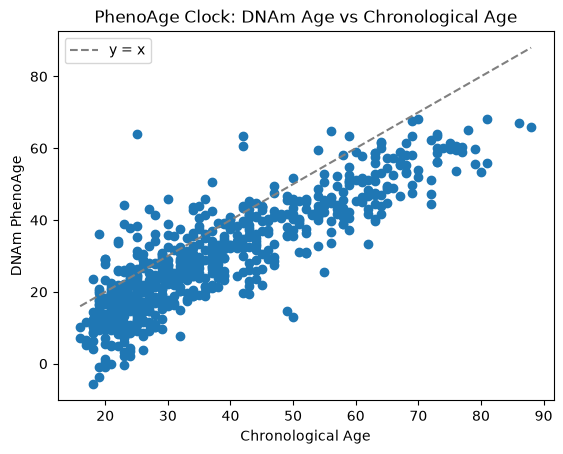

In [6]:
plt.scatter(comparison["ChronAge"], comparison["DNAmAge"])
plt.xlabel("Chronological Age")
plt.ylabel("DNAm PhenoAge")
plt.plot(
    [comparison["ChronAge"].min(), comparison["ChronAge"].max()],
    [comparison["ChronAge"].min(), comparison["ChronAge"].max()],
    linestyle="--", color="grey", label="y = x",
)
plt.legend()
plt.title("PhenoAge Clock: DNAm Age vs Chronological Age")
plt.show()

## 5. Validate against published (paper) results

Compare the metrics computed above against the values published for this
dataset in Levine et al. (2018)'s supplementary tables.

In [22]:
paper_results = {
    "Cor(Age, DNAmPhenoAge)" : 0.85, 
    "Median Absolute Error (years)" : 5.0 , 
    "Median Age Acceleration" : np.nan
}

In [23]:
validation = clock.validate(
    metrics,
    pd.DataFrame(paper_results , index=[0]),
    dataset_name=None,
)
validation


  Clock Validation — None
                          Yours  Paper  Abs. Diff  Tolerance  Status
Metric                                                              
Cor(Age, DNAmPhenoAge)   0.8675   0.85     0.0175       0.05  ✓ Pass
Median Absolute Error    8.3160   5.00     3.3160       0.50  ✗ Fail
Median Age Acceleration -7.6740    NaN        NaN       0.50  ✗ Fail
  ✗ Outside tolerance: Median Absolute Error, Median Age Acceleration
  Check: CpG preprocessing, age transformation,
         sample filtering, or training CpG selection.



,Yours,Paper,Abs. Diff,Tolerance,Status
Metric,,,,,
"Cor(Age, DNAmPhenoAge)",0.8675,0.85,0.0175,0.05,✓ Pass
Median Absolute Error,8.3160,5.00,3.3160,0.50,✗ Fail
Median Age Acceleration,-7.6740,NaN,NaN,0.50,✗ Fail


## 6. (Optional) One-shot pipeline

`PhenoAge.run()` bundles prediction + comparison + metrics into a single call,
useful once you trust the individual steps above.

In [24]:
out = clock.run(methylation, chron_ages=chron_ages, age_accel_method="difference")
out["metrics"]

,"Cor(Age, DNAmPhenoAge)",Median Absolute Error (years),Median Age Acceleration
0,0.8675,8.316,-7.674
